# E9: PANNs CNN14 (pretrained AudioSet), fine-tune
Nhánh GitHub: `12-E9-panns-cnn14`

Mô hình tham chiếu ngoài E1–E8, cùng cách chia 5 fold. Âm thanh 32 kHz, Log-Mel 64 bins (n_fft 1024, hop 320), fine-tune toàn mạng (lr 1e-4 phần pretrain, 1e-3 lớp cuối), SpecAugment + Mixup, FP16. Cần internet để tải trọng số (khoảng 330 MB). Kết quả E9 không dùng để trả lời RQ1–RQ3.

In [1]:
!pip -q install soundfile
from google.colab import drive
drive.mount('/content/drive')
import sys
sys.path.append('/content/drive/MyDrive/ESC50')
from esc_lib import *
setup()

Mounted at /content/drive
GPU: Tesla T4 | VRAM 15.6 GB | torch 2.14.1+cu130 | CUDA 13.0
RAM trống 11.8 GB | ổ đĩa trống 120.8 GB
Mixup: BẬT | quick: False | kết quả lưu ở: /content/drive/MyDrive/ESC50/results_mixup


In [2]:
meta, X, X_DEV, y, folds = load_data()
X32_DEV = get_x32()
panns_state = load_panns()

  0%|          | 0/2000 [00:00<?, ?it/s]

X: (2000, 110250) | y: (2000,) | nằm trên: cuda:0


Đọc 32 kHz:   0%|          | 0/2000 [00:00<?, ?it/s]

100%|██████████| 312M/312M [02:18<00:00, 2.36MB/s]


Đã nạp trọng số pretrain: 84 tensor


### Kiểm tra tiền xử lý của mô hình pretrain (D4)

In [3]:
def debug_pretrained_preprocessing():
    state = panns_state

    front = PannsFront().to(DEVICE).eval()
    mel = front.mel
    expected = dict(sample_rate=32000, n_fft=1024, win_length=1024, hop_length=320, n_mels=64, f_min=50.0, f_max=14000.0)
    print("D4.1 Thông số Log-Mel so với cấu hình PANNs CNN14 (thông số đã công bố):")
    for k, v in expected.items():
        now = getattr(mel, k, None)
        print(f"    {k:<12} hiện tại {now} | PANNs {v} | {'OK' if now is None or now == v else 'KHÁC!'}")
        assert now is None or now == v, f"Thông số {k} khác với PANNs"

    model = PannsNet(CFG["NUM_CLASSES"])
    res = model.load_state_dict(state, strict=False)
    missing = [k for k in res.missing_keys if not k.startswith("fc_out")]
    print(f"D4.2 Nạp trọng số: thiếu {len(res.missing_keys)} khóa (chỉ được phép thiếu fc_out), "
          f"khóa dư {len(res.unexpected_keys)} (lớp phân loại AudioSet và bộ trích đặc trưng gốc, bỏ qua)")
    assert not missing, f"Thiếu trọng số: {missing[:5]}"

    wav = X32_DEV[:8].to(DEVICE)
    with torch.no_grad():
        spec = front(wav)
    amp = wav.abs().max().item()
    print(f"D4.3 Biên độ wav lớn nhất {amp:.3f} (thang [-1, 1]; vượt 1 một chút là bình thường vì bộ lọc resample 44,1 kHz xuống 32 kHz "
          f"làm vọt biên ở clip rất to)")
    print(f"     Log-Mel {tuple(spec.shape)} dạng dB: min {spec.min().item():.1f}, max {spec.max().item():.1f}, "
          f"mean {spec.mean().item():.1f} (kỳ vọng trong khoảng -100 đến +60; không chuẩn hóa thêm vì lớp bn0 của PANNs tự chuẩn hóa)")
    assert torch.isfinite(spec).all(), "Log-Mel có NaN/Inf"
    assert amp <= 2.0, f"Biên độ wav {amp:.2f} quá lớn, có thể dữ liệu chưa về thang [-1, 1]"
    assert -150 < spec.min().item() and spec.max().item() < 80, "Log-Mel nằm ngoài dải dB hợp lý"
    print("KẾT LUẬN D4: tiền xử lý cho E9 khớp với PANNs.")


debug_pretrained_preprocessing()

D4.1 Thông số Log-Mel so với cấu hình PANNs CNN14 (thông số đã công bố):
    sample_rate  hiện tại 32000 | PANNs 32000 | OK
    n_fft        hiện tại 1024 | PANNs 1024 | OK
    win_length   hiện tại 1024 | PANNs 1024 | OK
    hop_length   hiện tại 320 | PANNs 320 | OK
    n_mels       hiện tại 64 | PANNs 64 | OK
    f_min        hiện tại 50.0 | PANNs 50.0 | OK
    f_max        hiện tại 14000.0 | PANNs 14000.0 | OK
D4.2 Nạp trọng số: thiếu 2 khóa (chỉ được phép thiếu fc_out), khóa dư 5 (lớp phân loại AudioSet và bộ trích đặc trưng gốc, bỏ qua)
D4.3 Biên độ wav lớn nhất 1.236 (thang [-1, 1]; vượt 1 một chút là bình thường vì bộ lọc resample 44,1 kHz xuống 32 kHz làm vọt biên ở clip rất to)
     Log-Mel (8, 1, 64, 501) dạng dB: min -100.0, max 23.9, mean -41.4 (kỳ vọng trong khoảng -100 đến +60; không chuẩn hóa thêm vì lớp bn0 của PANNs tự chuẩn hóa)
KẾT LUẬN D4: tiền xử lý cho E9 khớp với PANNs.


### Huấn luyện 5 fold

In [4]:
runs, rob = run_exp("E9")

E9 | fold 1:   0%|          | 0/30 [00:00<?, ?it/s]

[E9 | fold 1] acc 0.9400 | macro-F1 0.9363 | lr 0.0001 | epoch tốt nhất 19 | 267s


E9 | fold 2:   0%|          | 0/30 [00:00<?, ?it/s]

[E9 | fold 2] acc 0.9750 | macro-F1 0.9750 | lr 0.0001 | epoch tốt nhất 23 | 249s


E9 | fold 3:   0%|          | 0/30 [00:00<?, ?it/s]

[E9 | fold 3] acc 0.9325 | macro-F1 0.9312 | lr 0.0001 | epoch tốt nhất 19 | 249s


E9 | fold 4:   0%|          | 0/30 [00:00<?, ?it/s]

[E9 | fold 4] acc 0.9325 | macro-F1 0.9315 | lr 0.0001 | epoch tốt nhất 19 | 249s


E9 | fold 5:   0%|          | 0/30 [00:00<?, ?it/s]

[E9 | fold 5] acc 0.9100 | macro-F1 0.9048 | lr 0.0001 | epoch tốt nhất 15 | 248s


### Kết quả

,fold,acc,macro_f1,lr,best_epoch,val_f1,train_time
0,1,0.9400,0.9363,0.0001,19,0.9725,267.4675
1,2,0.9750,0.9750,0.0001,23,0.9226,248.9379
2,3,0.9325,0.9312,0.0001,19,0.9568,249.2198
3,4,0.9325,0.9315,0.0001,19,0.9387,248.9231
4,5,0.9100,0.9048,0.0001,15,0.9431,248.4627


E9: Accuracy 93.80 ± 2.35 | Macro-F1 93.57 ± 2.52 | 79,776,242 tham số


,acc,macro_f1
condition,,
Sạch,93.80,93.57
20 dB,89.30,88.80
10 dB,77.65,77.71
0 dB,43.40,47.04


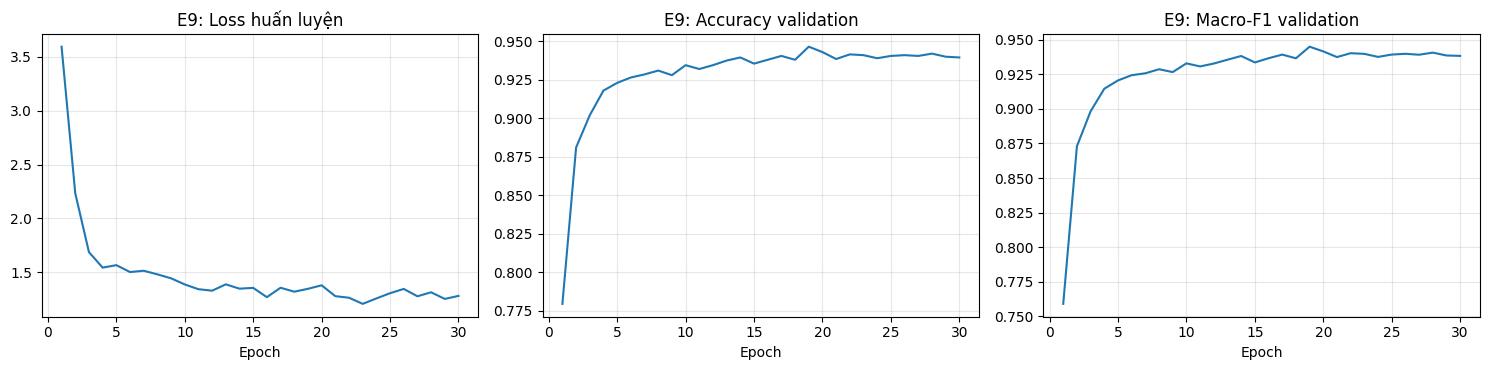

In [5]:
show_exp("E9")